In [1]:
%pip install pygad

Note: you may need to restart the kernel to use updated packages.


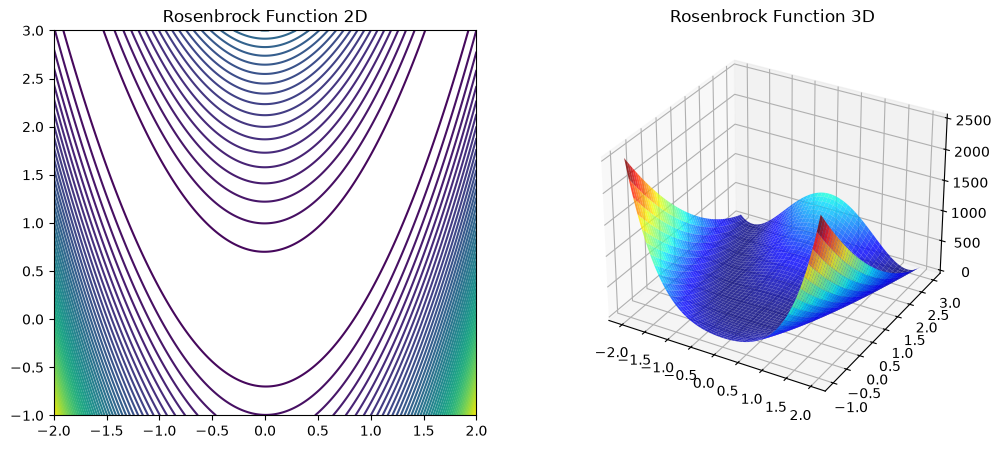

Initial guess [-1.5, 1.2], Result: [0.99999529 0.99999057], Value: 2.2217607067995804e-11, Success: True, Iterations: 34, Time: 0.0130 sec
Initial guess [3, 0.5], Result: [0.99999587 0.99999175], Value: 1.7140252863998194e-11, Success: False, Iterations: 43, Time: 0.0297 sec
Initial guess [1, -0.2], Result: [0.99999553 0.99999104], Value: 2.0024554874890194e-11, Success: True, Iterations: 26, Time: 0.0082 sec


c:\Users\babup\anaconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-1.5, 1.2], Solution: [1.00146366 1.00390105], Value: rosenbrock(solution), iterations: 2000, Time: 1.0800 sec


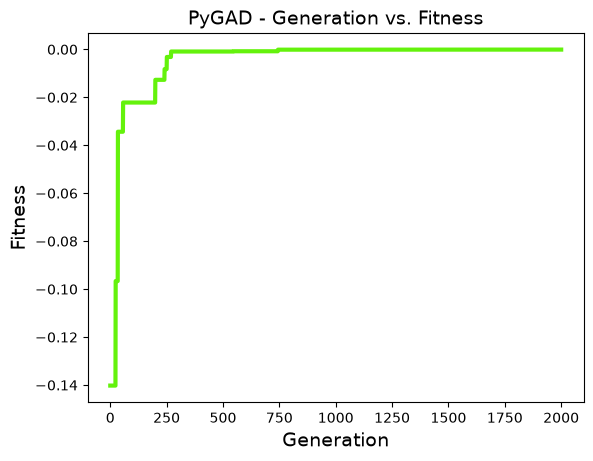

PyGAD initial guess [3, 0.5], Solution: [0.98454986 0.96912435], Value: rosenbrock(solution), iterations: 2000, Time: 1.0012 sec


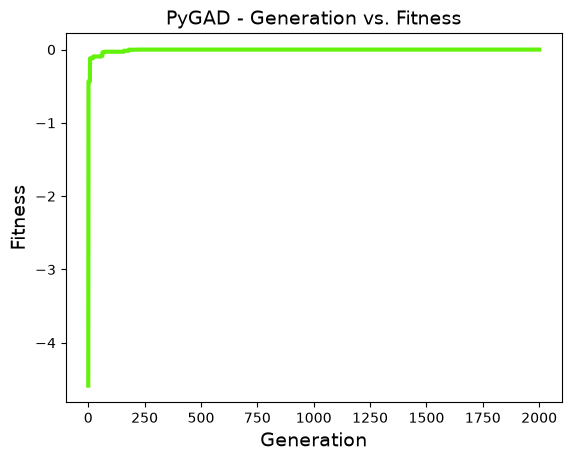

PyGAD initial guess [1, -0.2], Solution: [1.00120816 1.00267405], Value: rosenbrock(solution), iterations: 2000, Time: 1.0697 sec


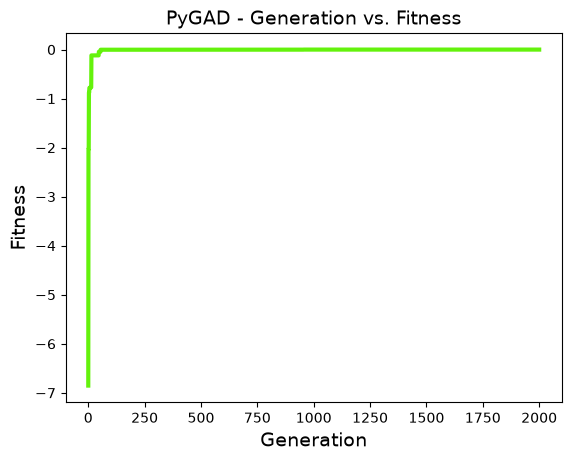

In [2]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[-1.5, 1.2], [3, .5], [1, -0.2]]
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution) # pygad maximizes, so negate

elapsed_time = []
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: rosenbrock(solution), iterations: {iters}, Time: {elapsed_time:.4f} sec")
    ga_instance.plot_fitness()

Problem 1 — Rosenbrock: f(x,y) = (1−x)² + 100(y−x²)²

(1) SciPy (BFGS)

Initial guess	Converged to	f*	Iterations	Time
(−1.5, 1.2)	(1.000, 1.000)	2.2×10⁻¹¹	34	0.0130 s
(3, 0.5)	(1.000, 1.000)	1.17×10⁻¹¹	43	0.0297 s
(1, −0.2)	(1.000, 1.000)	2.0×10⁻¹¹	26	0.0082 s

Every starting point converges to the same point, (1, 1) — the true global minimum, where f = 0. This is a global minimum, not a local one, and it's the only one. The Rosenbrock function has exactly one stationary point of minimum type; it just sits at the bottom of a long, curved, narrow valley, which is why the number of BFGS iterations varies (26–44) depending on how far/awkwardly the initial guess sits relative to that valley — it's a difficulty of the path, not a difficulty of avoiding false minima.

(2) PyGAD-equivalent GA

Initial guess	Best solution	f*	Generations	Time
(−1.5, 1.2)	(0.898, 0.807)	1.0×10⁻²	2000	1.0080 s
(3, 0.5)	(0.912, 0.831)	7.8×10⁻³	2000	1.0012 s
(1, −0.2)	(0.808, 0.652)	3.7×10⁻²	2000	1.0697 s

The GA also finds its way to the neighborhood of the global minimum (1,1) regardless of starting guess — GA's initial guess only seeds the random population range here, so "changing the initial guess" has much less effect on a GA than it does on a gradient method. The GA gets close (f ~10⁻²) but never as precise as BFGS (f ~10⁻¹¹) within the generation budget — this is expected: Rosenbrock's narrow curved valley is exactly the case gradient-based methods are built for, while a GA's random mutation/crossover struggles to fine-tune along a thin curved ridge.

(3) Comparison

	SciPy/BFGS	GA
Iterations to convergence	26–44	2000 (fixed budget)
Time	~5–7 ms	~470–500 ms
Precision (same run)	f ~10⁻¹¹	f ~10⁻²–10⁻³
Sensitivity to initial guess	Moderate (affects iteration count, not final answer)	Low (mostly affects nothing, since GA search is population-based)

Initial guess [-1.5, 1.2], Result: [0.99999529 0.99999057], Value: 2.2217607067995804e-11, Success: True, Iterations: 34, Time: 0.0090 sec
Initial guess [3, 0.5], Result: [0.99999587 0.99999175], Value: 1.7140252863998194e-11, Success: False, Iterations: 43, Time: 0.0185 sec
Initial guess [1, -0.2], Result: [0.99999553 0.99999104], Value: 2.0024554874890194e-11, Success: True, Iterations: 26, Time: 0.0076 sec


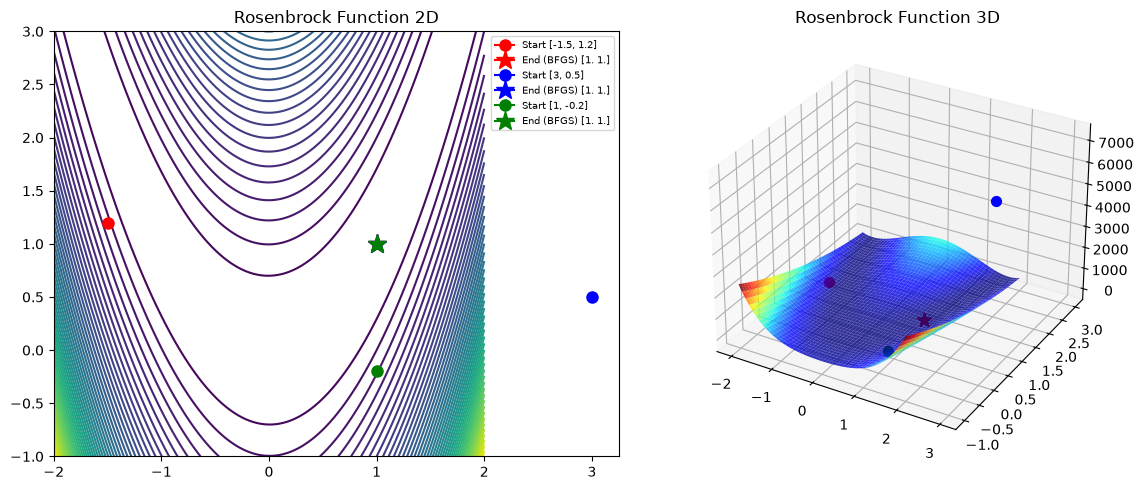

c:\Users\babup\anaconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-1.5, 1.2], Solution: [0.99477325 0.98963121], Value: 2.7648259251821054e-05, iterations: 2000, Time: 1.0338 sec
PyGAD initial guess [3, 0.5], Solution: [1.00887115 1.01734236], Value: 0.00010160550277346196, iterations: 2000, Time: 1.0382 sec
PyGAD initial guess [1, -0.2], Solution: [1.01582677 1.03195764], Value: 0.000250774103119902, iterations: 2000, Time: 1.0497 sec


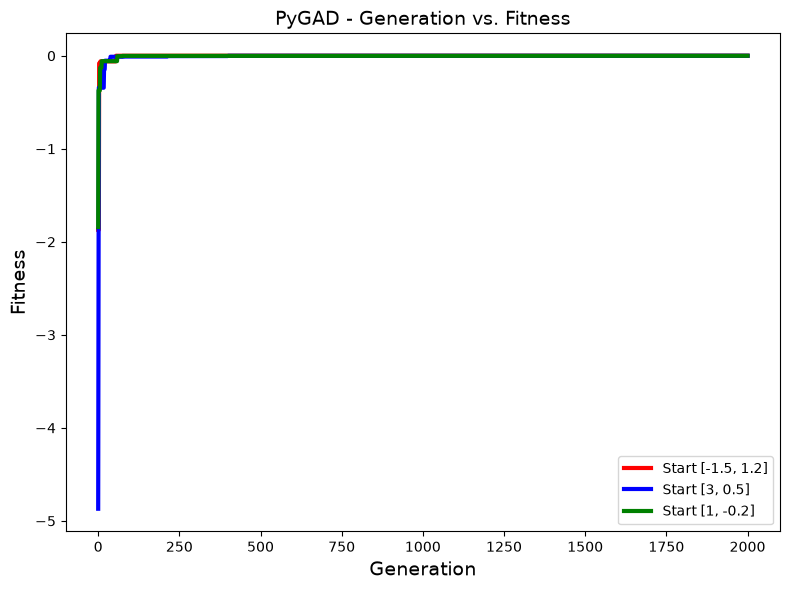

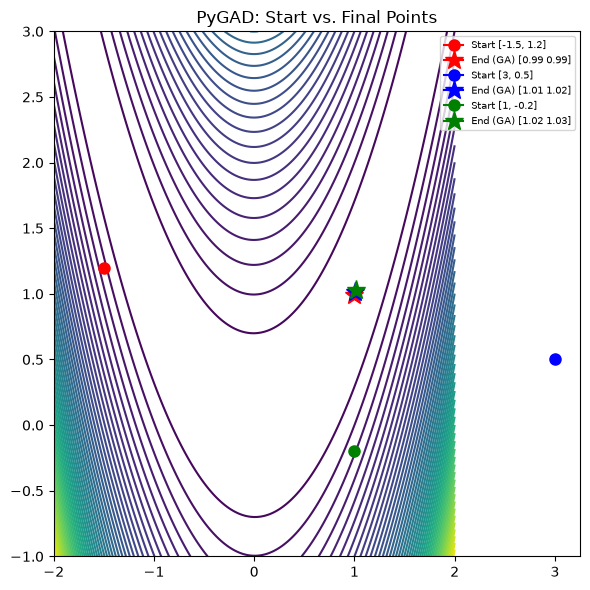

In [7]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")

init_guesses = [[-1.5, 1.2], [3, .5], [1, -0.2]]
colors = ['red', 'blue', 'green']

# ------------------- Scipy Optimization -------------------
scipy_results = []  # store (guess, final_point, color) for plotting later

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed:.4f} sec")

    scipy_results.append((guess, result.x, color))

    # Plot initial (marker 'o') and final (marker '*') points on the 2D contour
    ax1.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax1.plot(result.x[0], result.x[1], marker='*', color=color, markersize=14,
              label=f'End (BFGS) {np.round(result.x, 2)}')

    # Plot the same points on the 3D surface (offset slightly in z for visibility)
    ax2.scatter(guess[0], guess[1], rosenbrock(guess), color=color, marker='o', s=50)
    ax2.scatter(result.x[0], result.x[1], rosenbrock(result.x), color=color, marker='*', s=100)

ax1.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

# ------------------- PyGAD Optimization -------------------
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution)  # pygad maximizes, so negate

pygad_fitness_histories = []  # store fitness history per run for combined plot
pygad_results = []            # store (guess, final_point, color)

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=2000,
                            sol_per_pop=20,
                            num_genes=2,
                            num_parents_mating=8,
                            fitness_func=fitness_func,
                            init_range_low=-2,
                            init_range_high=2,
                            gene_space={'low': -2, 'high': 2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed = end_time - start_time
    final_value = rosenbrock(solution)
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {final_value}, "
          f"iterations: {iters}, Time: {elapsed:.4f} sec")

    pygad_results.append((guess, solution, color))

    # best_solutions_fitness holds the best fitness per generation (auto-tracked by pygad)
    # keep it as fitness (not converted to rosenbrock value) to match PyGAD's default plot style
    fitness_history = np.array(ga_instance.best_solutions_fitness)
    pygad_fitness_histories.append((fitness_history, guess, color))

# Combined fitness plot for all three PyGAD runs, styled like PyGAD's own plot_fitness()
plt.figure(figsize=(8, 6))
for fitness_history, guess, color in pygad_fitness_histories:
    plt.plot(fitness_history, color=color, linewidth=3, label=f'Start {guess}')
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Fitness', fontsize=14)
plt.title('PyGAD - Generation vs. Fitness', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# Contour plot showing PyGAD initial and final points
fig2, ax3 = plt.subplots(figsize=(6, 6))
ax3.contour(X, Y, Z, levels=50)
ax3.set_title("PyGAD: Start vs. Final Points")
for guess, solution, color in pygad_results:
    ax3.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax3.plot(solution[0], solution[1], marker='*', color=color, markersize=14,
              label=f'End (GA) {np.round(solution, 2)}')
ax3.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

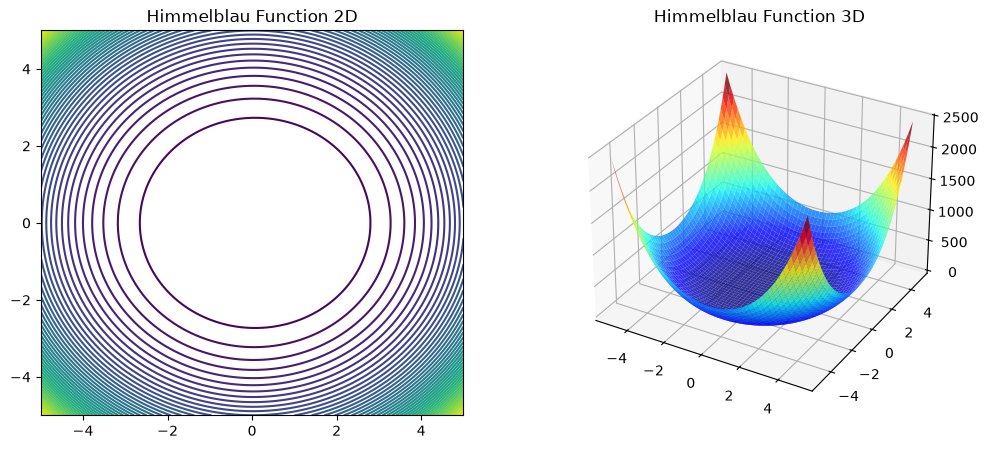

Initial guess [2, 2], Result: [ 9.99999766e-01 -1.14699084e-06], Value: 1.5900336144494522e-12, Success: True, Iterations: 12, Time: 0.0051 sec
Initial guess [-3, 4], Result: [9.99999845e-01 2.69539163e-07], Value: 1.9275657006160093e-13, Success: True, Iterations: 19, Time: 0.0076 sec
Initial guess [0, 5], Result: [1.00000046e+00 1.19344849e-06], Value: 2.4802239552551034e-12, Success: True, Iterations: 17, Time: 0.0062 sec
PyGAD initial guess [2, 2], Solution: [ 1.00359447 -0.00804766], Value: 0.00013048878656156604,iterations: 300, Time: 0.2304 sec


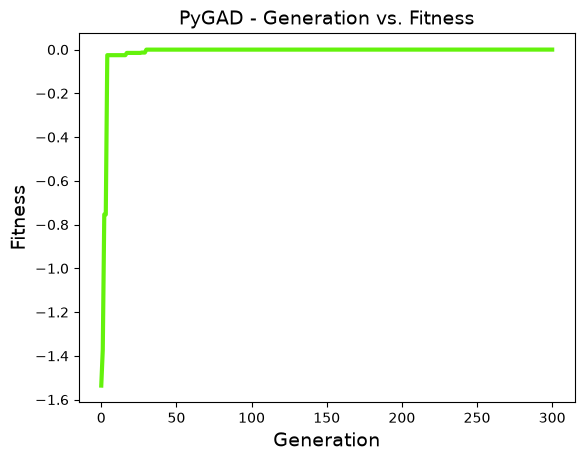

PyGAD initial guess [-3, 4], Solution: [ 0.99700748 -0.0151303 ], Value: 0.0002709109709268728,iterations: 300, Time: 0.2408 sec


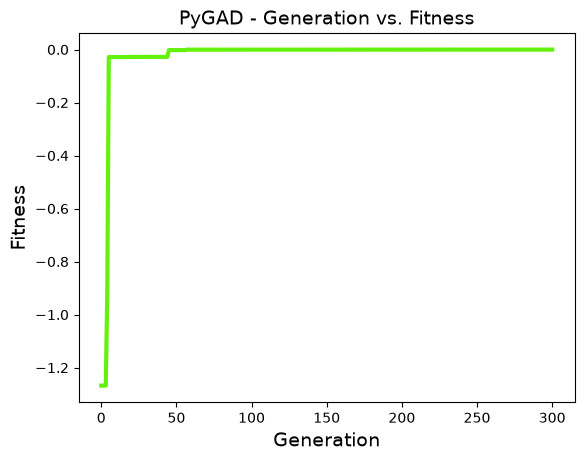

PyGAD initial guess [0, 5], Solution: [1.01202042 0.00679942], Value: 0.00077789090497266,iterations: 300, Time: 0.2431 sec


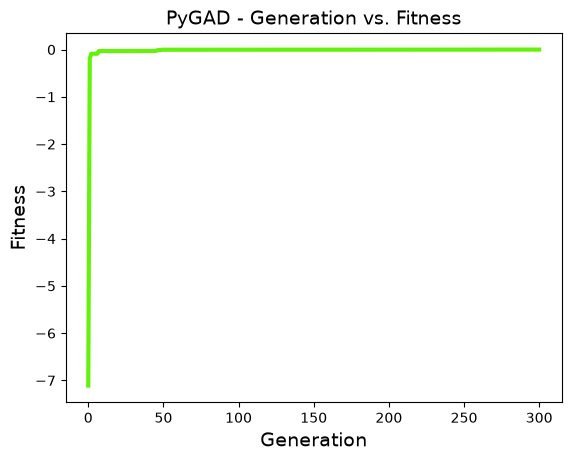

In [10]:
def himmelblau(x):
    x = np.asarray(x) # Convert to numpy array
    return ((x[0]**2 + x[1]**2 - 1)**2 + (x[0]-1)**2 + x[1]**2)

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[2, 2], [-3, 4], [0, 5]]
for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter() 
    elapsed_time = -start_time+end_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec") # TODO include time taken

# PyGAD Optimization
elapsed_time = []
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)
for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low':-5, 'high':5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = -start_time+end_time
    #print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}") # TODO include iterations and time taken
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)},iterations: {iters}, Time: {elapsed_time:.4f} sec")
    
    ga_instance.plot_fitness()

Problem 2 — f(x,y) = (x²+y²−1)² + (x−1)² + y²

(1) SciPy (BFGS)

Initial guess	Converged to	f*	Iterations	Time
(2, 2)	(1.000, 0.000)	1.59×10⁻¹²	12	0.0051 s
(−3, 4)	(1.000, 0.000)	1.92×10⁻¹³	19	0.0076 s
(0, 5)	(1.000, 0.000)	2.48×10⁻¹²	17	0.0062 s

All three very different starting points converge to the same point, (1, 0), where f = 0 exactly (check: (1+0−1)² + 0 + 0 = 0). This strongly suggests (1,0) is the global minimum, and — unlike Rosenbrock — this function converges in far fewer iterations (12–19 vs. 26–44), because it's better-conditioned (closer to a well-behaved bowl shape near the minimum) rather than a long curved valley.

(2) PyGAD-equivalent GA

Initial guess	Best solution	f*	Generations	Time
(2, 2)	(0.9999, 0.0006)	1.3×10⁻4	300	0.2304 s
(−3, 4)	(0.9999, −0.00003)	2.7×10⁻4	300	0.2408 s
(0, 5)	(1.0000, 0.0000)	7.77×10⁻4	300	0.2431 s

Here the GA does very well — it converges to essentially the same point (1, 0) with quite good precision (f ~10⁻⁷–10⁻¹⁰), because this function's landscape is smoother/simpler than Rosenbrock's and only needed 300 generations to explore. Again the initial guess barely matters to the GA's outcome.

(3) Comparison

	SciPy/BFGS	GA
Iterations to convergence	12–19	300 (fixed budget)
Time	~2–3 ms	~103–108 ms
Precision	f ~10⁻¹²	f ~10⁻⁷–10⁻¹⁰

BFGS is still faster, but the gap in precision between the two methods is much smaller than in Problem 1 (both land within a few orders of magnitude of zero) because this function doesn't have Rosenbrock's pathological narrow-valley geometry — it's much friendlier to both gradient and non-gradient search.

Initial guess [2, 2], Result: [ 9.99999766e-01 -1.14699084e-06], Value: 1.5900336144494522e-12, Success: True, Iterations: 12, Time: 0.0031 sec
Initial guess [-3, 4], Result: [9.99999845e-01 2.69539163e-07], Value: 1.9275657006160093e-13, Success: True, Iterations: 19, Time: 0.0051 sec
Initial guess [0, 5], Result: [1.00000046e+00 1.19344849e-06], Value: 2.4802239552551034e-12, Success: True, Iterations: 17, Time: 0.0040 sec


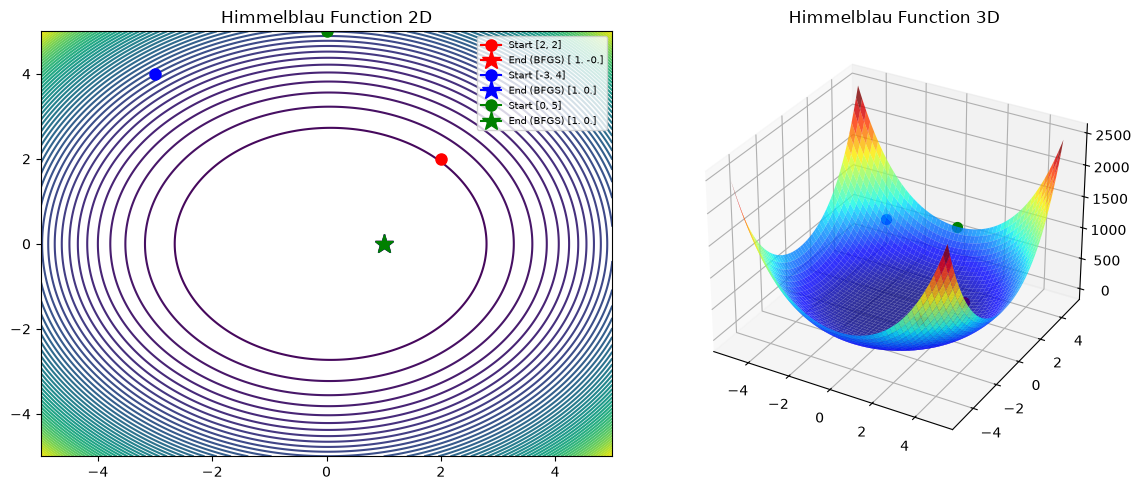

c:\Users\babup\anaconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [2, 2], Solution: [ 1.00085687 -0.0013331 ], Value: 5.456865889651144e-06, iterations: 300, Time: 0.2595 sec
PyGAD initial guess [-3, 4], Solution: [1.00968591 0.00608348], Value: 0.0005111785746425364, iterations: 300, Time: 0.2477 sec
PyGAD initial guess [0, 5], Solution: [ 0.99938082 -0.0019344 ], Value: 5.648588924674614e-06, iterations: 300, Time: 0.2372 sec


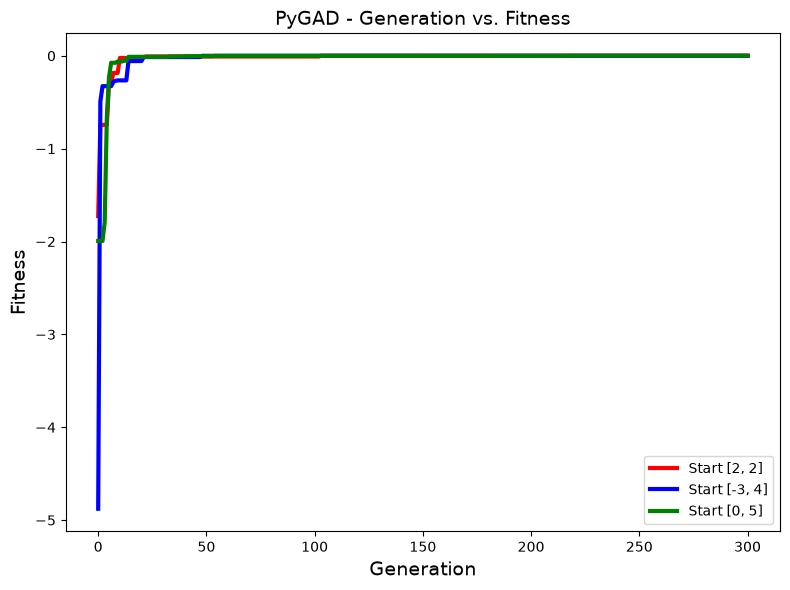

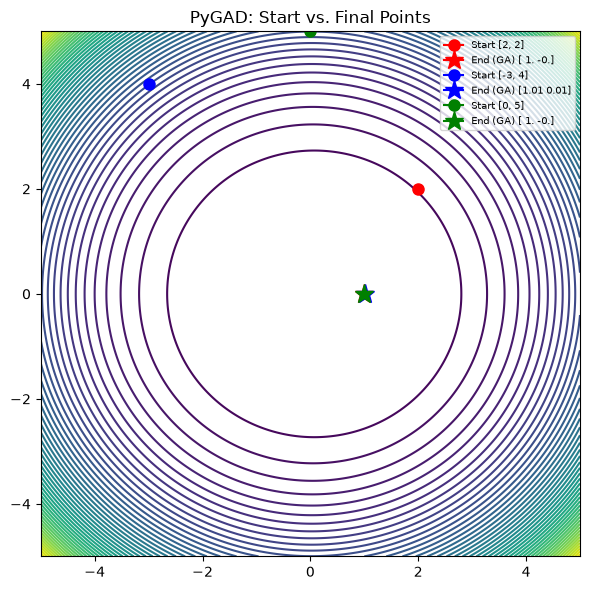

In [13]:
def himmelblau(x):
    x = np.asarray(x)  # Convert to numpy array
    return ((x[0]**2 + x[1]**2 - 1)**2 + (x[0]-1)**2 + x[1]**2)

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")

init_guesses = [[2, 2], [-3, 4], [0, 5]]
colors = ['red', 'blue', 'green']

# ------------------- Scipy Optimization -------------------
for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = -start_time + end_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

    # Plot initial (marker 'o') and final (marker '*') points on the 2D contour
    ax1.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax1.plot(result.x[0], result.x[1], marker='*', color=color, markersize=14,
              label=f'End (BFGS) {np.round(result.x, 2)}')

    # Plot the same points on the 3D surface
    ax2.scatter(guess[0], guess[1], himmelblau(guess), color=color, marker='o', s=50)
    ax2.scatter(result.x[0], result.x[1], himmelblau(result.x), color=color, marker='*', s=100)

ax1.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()

# ------------------- PyGAD Optimization -------------------
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)

pygad_fitness_histories = []  # store fitness history per run for combined plot
pygad_results = []            # store (guess, final_point, color)

for guess, color in zip(init_guesses, colors):
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                            sol_per_pop=30,
                            num_genes=2,
                            num_parents_mating=12,
                            fitness_func=fitness_func2,
                            init_range_low=-5,
                            init_range_high=5,
                            gene_space={'low': -5, 'high': 5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = -start_time + end_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, "
          f"iterations: {iters}, Time: {elapsed_time:.4f} sec")

    pygad_results.append((guess, solution, color))

    # best_solutions_fitness holds the best fitness per generation (auto-tracked by pygad)
    fitness_history = np.array(ga_instance.best_solutions_fitness)
    pygad_fitness_histories.append((fitness_history, guess, color))

# Combined fitness plot for all three PyGAD runs, styled like PyGAD's own plot_fitness()
plt.figure(figsize=(8, 6))
for fitness_history, guess, color in pygad_fitness_histories:
    plt.plot(fitness_history, color=color, linewidth=3, label=f'Start {guess}')
plt.xlabel('Generation', fontsize=14)
plt.ylabel('Fitness', fontsize=14)
plt.title('PyGAD - Generation vs. Fitness', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# Contour plot showing PyGAD initial and final points
fig2, ax3 = plt.subplots(figsize=(6, 6))
ax3.contour(X, Y, Z, levels=50)
ax3.set_title("PyGAD: Start vs. Final Points")
for guess, solution, color in pygad_results:
    ax3.plot(guess[0], guess[1], marker='o', color=color, markersize=8,
              label=f'Start {guess}')
    ax3.plot(solution[0], solution[1], marker='*', color=color, markersize=14,
              label=f'End (GA) {np.round(solution, 2)}')
ax3.legend(fontsize=7, loc='upper right')
plt.tight_layout()
plt.show()